# EVA-X-Tiny: three frozen pretrained pipelines
**Validation gate:** the official checkpoint smoke test must pass before any real-data experiment. Architecture-only tests pass with timm 0.9.16 / torch 2.5.1 / torchvision 0.20.1. The README-suggested timm 0.9.0 fails the official forward pass (missing `_pos_embed`). The cloud proxy blocks Hugging Face with HTTP 403. Thus official pretrained loading, 192D pretrained features and full experiments are **not locally validated**. No results are prefilled. A successful Colab execution must establish these properties rather than assume them.

Compare DenseNet Lung Opacity + OLS, ResNet18 ImageNet 512D + Ridge, and EVA-X-Tiny CXR 192D + Ridge. No prior notebook or result is modified. Outputs: `/content/duong-eva-x-results/`.


In [2]:
!git clone --branch eva-x-comparison \
https://github.com/ZIYINGLAN/nus_DSA5206_GROUPPROJECT.git \
/content/nus_DSA5206_GROUPPROJECT

Cloning into '/content/nus_DSA5206_GROUPPROJECT'...
remote: Enumerating objects: 98, done.
remote: Counting objects: 100% (98/98), done.
remote: Compressing objects: 100% (83/83), done.
remote: Total 98 (delta 31), reused 42 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (98/98), 11.26 MiB | 13.78 MiB/s, done.
Resolving deltas: 100% (31/31), done.


In [ ]:
# Colab: run once, restart runtime if requested, then continue below.
%pip install torch==2.5.1 torchvision==0.20.1 torchxrayvision==1.4.0 numpy==1.26.4 pandas==2.2.3 scipy==1.14.1 scikit-learn==1.5.2 scikit-image==0.24.0 matplotlib==3.9.2 timm==0.9.16


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.8/60.8 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 906.5/906.5 MB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 46.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 MB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 25.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.9/14.9 MB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 33.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 

In [2]:
!git clone --branch eva-x-comparison \
https://github.com/ZIYINGLAN/nus_DSA5206_GROUPPROJECT.git \
/content/nus_DSA5206_GROUPPROJECT

fatal: destination path '/content/nus_DSA5206_GROUPPROJECT' already exists and is not an empty directory.


In [3]:
%cd /content/nus_DSA5206_GROUPPROJECT

!git fetch origin
!git switch eva-x-comparison
!git pull origin eva-x-comparison

/content/nus_DSA5206_GROUPPROJECT
Already on 'eva-x-comparison'
Your branch is up to date with 'origin/eva-x-comparison'.
From https://github.com/ZIYINGLAN/nus_DSA5206_GROUPPROJECT
 * branch            eva-x-comparison -> FETCH_HEAD
Already up to date.


In [4]:
import sys
import importlib.util
import importlib.machinery
from pathlib import Path

repo = Path("/content/nus_DSA5206_GROUPPROJECT").resolve()

def load_module(name):
    path = repo / f"{name}.py"

    assert path.is_file(), f"File not found: {path}"

    loader = importlib.machinery.SourceFileLoader(
        name, str(path)
    )

    spec = importlib.util.spec_from_loader(
        name, loader
    )

    module = importlib.util.module_from_spec(spec)

    # 注册模块，供其他 Python 文件 import
    sys.modules[name] = module

    try:
        loader.exec_module(module)
    except Exception:
        sys.modules.pop(name, None)
        raise

    print(f"Successfully loaded: {name}")
    return module

# 按依赖顺序加载
critical_methods = load_module("critical_methods")
resnet18_methods = load_module("resnet18_methods")
eva_x_methods = load_module("eva_x_methods")

print("\nAll three modules loaded successfully!")

Successfully loaded: critical_methods
Successfully loaded: resnet18_methods
Successfully loaded: eva_x_methods

All three modules loaded successfully!


In [5]:
import sys
import os
from pathlib import Path

repo = Path("/content/nus_DSA5206_GROUPPROJECT")

# 检查仓库是否存在
print("Repository exists:", repo.is_dir())

# 检查三个必需的模块
modules = [
    "critical_methods.py",
    "resnet18_methods.py",
    "eva_x_methods.py"
]

for name in modules:
    path = repo / name
    print(f"{name}: {path.is_file()}")

# 加入 Python 搜索路径
assert repo.is_dir(), "GitHub repository not found"

for name in modules:
    assert (repo / name).is_file(), f"Missing {name}"

sys.path.insert(0, str(repo.resolve()))
os.chdir(repo)

# 测试导入
import critical_methods
import resnet18_methods
import eva_x_methods

print("\nAll project modules loaded successfully!")

Repository exists: True
critical_methods.py: True
resnet18_methods.py: True
eva_x_methods.py: True

All project modules loaded successfully!


In [3]:
# Optional: mount Drive before configuring historical data.
from google.colab import drive
drive.mount('/content/drive')
import os,sys,json,platform,importlib.metadata,shutil
from pathlib import Path
from time import perf_counter
from urllib.parse import urlparse
REPO_DIR=Path(os.environ.get('DUONG_REPO_DIR','/content/nus_DSA5206_GROUPPROJECT')).resolve()
DATA_DIR=Path(os.environ.get('DUONG_DATA_DIR','/content/drive/MyDrive/duong-data')).resolve()
IMAGE_DIR=Path(os.environ.get('DUONG_IMAGE_DIR',str(DATA_DIR/'images')))
METADATA_CSV=Path(os.environ.get('DUONG_METADATA_CSV',str(DATA_DIR/'metadata_2020.csv')))
SCORES_CSV=Path(os.environ.get('DUONG_SCORES_CSV',str(DATA_DIR/'covid-severity-scores.csv')))
ASSESSMENT_DIR=Path(os.environ.get('DUONG_CRITICAL_RESULTS_DIR','/content/duong-critical-assessment-results'))
REPRO_DIR=Path(os.environ.get('DUONG_REPRO_RESULTS_DIR','/content/duong-improved-results'))
RESNET_RESULTS_DIR=Path(os.environ.get('DUONG_RESNET_RESULTS_DIR','/content/duong-resnet18-results'))
OUTPUT_DIR=Path('/content/duong-eva-x-results/').resolve()
assert OUTPUT_DIR!=REPO_DIR and REPO_DIR not in OUTPUT_DIR.parents
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
sys.path.insert(0,str(REPO_DIR));os.chdir(OUTPUT_DIR)
INCLUDE_PCA=False # three prespecified primary pipelines only
import torch,numpy as np,pandas as pd
from PIL import Image
from threadpoolctl import threadpool_limits
from IPython.display import display
from critical_methods import sha256_file,fingerprint,exact_splits
from resnet18_methods import (BASELINE,RIDGE,ALPHAS,SCATTER_SEED,validate_heldout_records,
    paired_alignment,compare_models,aligned_features)
from eva_x_methods import (official_source,official_checkpoint,pretrained_smoke,pooled_features,
    evaluation_transform,PREPROCESSING,OFFICIAL_COMMIT,EVA_MODEL,evaluate_eva,verify_prior_identity)
torch.set_num_threads(2)


Mounted at /content/drive


## Smoke test first: official model, weights and CXR preprocessing
The pinned official `eva_x.py` factory `eva_x_tiny_patch16` is called unchanged. Its permissive loading is audited: **every non-head backbone tensor must match the filtered checkpoint in key, shape and value**; missing backbone tensors stop execution. Missing random classification-head weights are reported and unused.

Use `forward_head(forward_features(x), pre_logits=True)`: mean of patch tokens excluding prefix tokens, followed by the official `fc_norm`; no classification logits or flattened token sequence. Freeze all parameters, eval mode, inference_mode. Repeat the same synthetic grayscale image and require bitwise-equal finite (1,192) output. Record warnings, checkpoint SHA, device and versions.

Preprocessing follows pinned `classification/utils/datasets.py` **non-CheXpert CXR14 evaluation**: official PIL RGB conversion (grayscale is naturally replicated), bicubic shorter-edge resize 256, center crop 224, tensor [0,1], mean=0.49185243/std=0.28509309 per channel. The official CheXpert-Tiny branch instead resizes to 224 before cropping. There is no uniquely specified COVID severity policy; CXR14 is prespecified here, not selected on test outcomes. No ImageNet normalization is substituted.


In [10]:
import numpy as np
import torch
from torch.serialization import add_safe_globals

add_safe_globals([
    np.core.multiarray.scalar,
    np.dtype,
    type(np.dtype("float64")),
    type(np.dtype("float32")),
    type(np.dtype("int64")),
])

print("NumPy checkpoint types allowlisted")

NumPy checkpoint types allowlisted


/tmp/ipython-input-10-1429455714.py:6: DeprecationWarning: numpy.core is deprecated and has been renamed to numpy._core. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.multiarray.
  np.core.multiarray.scalar,


In [11]:
import sys
import torch
import numpy as np

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)

import eva_x_methods

print("Module path:", eva_x_methods.__file__)
print("Safe globals:", eva_x_methods.checkpoint_safe_globals())

Python: 3.11.13
PyTorch: 2.6.0+cu124
NumPy: 2.0.2
Module path: /content/nus_DSA5206_GROUPPROJECT/eva_x_methods.py
Safe globals: [<built-in function scalar>, <class 'numpy.dtype'>, <class 'numpy.dtypes.Float64DType'>]


In [12]:
import sys
import importlib.util
import numpy as np
from pathlib import Path

repo = Path("/content/nus_DSA5206_GROUPPROJECT")
module_path = repo / "eva_x_methods.py"

assert module_path.is_file(), "eva_x_methods.py not found"

# 强制加载磁盘上的项目模块
spec = importlib.util.spec_from_file_location(
    "eva_x_methods",
    str(module_path)
)

eva_module = importlib.util.module_from_spec(spec)
sys.modules["eva_x_methods"] = eva_module
spec.loader.exec_module(eva_module)

# 为经过官方 SHA256 校验的 checkpoint
# 补充已知的安全元数据类型
original_globals = eva_module.checkpoint_safe_globals

def checkpoint_safe_globals_fixed():
    return list(dict.fromkeys(
        original_globals() + [
            np.core.multiarray.scalar,
            np.dtype,
            type(np.dtype(np.float64)),
            set
        ]
    ))

eva_module.checkpoint_safe_globals = checkpoint_safe_globals_fixed

# 使用修复后的函数，避免旧的 from-import 引用
pretrained_smoke = eva_module.pretrained_smoke

print("Module:", eva_module.__file__)
print("Allowlist:", checkpoint_safe_globals_fixed())
print("Ready to retry smoke test")

Module: /content/nus_DSA5206_GROUPPROJECT/eva_x_methods.py
Allowlist: [<built-in function scalar>, <class 'numpy.dtype'>, <class 'numpy.dtypes.Float64DType'>, <class 'set'>]
Ready to retry smoke test


/tmp/ipython-input-12-1906142368.py:28: DeprecationWarning: numpy.core is deprecated and has been renamed to numpy._core. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.multiarray.
  np.core.multiarray.scalar,


In [15]:
import sys
import importlib.util
import numpy as np
import torch
from pathlib import Path

repo = Path("/content/nus_DSA5206_GROUPPROJECT")
module_path = repo / "eva_x_methods.py"

# 从磁盘重新加载当前项目模块
spec = importlib.util.spec_from_file_location(
    "eva_x_methods", module_path
)

eva_module = importlib.util.module_from_spec(spec)
sys.modules["eva_x_methods"] = eva_module
spec.loader.exec_module(eva_module)

print("NumPy version:", np.__version__)
print("PyTorch version:", torch.__version__)

# 使用明确的旧版序列化名称
# 解决 NumPy 2.x 中 numpy.core -> numpy._core 的变化
def fixed_checkpoint_safe_globals():
    scalar = np._core.multiarray.scalar if int(
        np.__version__.split(".")[0]
    ) >= 2 else np.core.multiarray.scalar

    return [
        (scalar, "numpy.core.multiarray.scalar"),
        np.dtype,
        type(np.dtype(np.float64)),
        set,
    ]

eva_module.checkpoint_safe_globals = (
    fixed_checkpoint_safe_globals
)

# 确保使用修复后的函数
pretrained_smoke = eva_module.pretrained_smoke

print("Safe global mappings:")
for item in fixed_checkpoint_safe_globals():
    print(item)

print("Compatibility patch applied!")

NumPy version: 2.0.2
PyTorch version: 2.6.0+cu124
Safe global mappings:
(<built-in function scalar>, 'numpy.core.multiarray.scalar')
<class 'numpy.dtype'>
<class 'numpy.dtypes.Float64DType'>
<class 'set'>
Compatibility patch applied!


In [17]:
# 修复报告生成时对 tuple 的处理

import eva_x_methods

original_load_eva_tiny = eva_module.load_eva_tiny

# 保留 PyTorch 支持的显式名称映射，
# 但让报告代码也能识别 tuple
class SafeGlobalEntry(tuple):
    @property
    def __module__(self):
        return self[1].rsplit(".", 1)[0]

    @property
    def __name__(self):
        return self[1].rsplit(".", 1)[1]

original_globals_fn = eva_module.checkpoint_safe_globals

def compatible_safe_globals():
    entries = original_globals_fn()
    return [
        SafeGlobalEntry(t) if isinstance(t, tuple) else t
        for t in entries
    ]

eva_module.checkpoint_safe_globals = compatible_safe_globals

pretrained_smoke = eva_module.pretrained_smoke

print("Safe globals report compatibility patch applied")

Safe globals report compatibility patch applied


In [18]:
eva, smoke_report = pretrained_smoke(
    source,
    checkpoint,
    checkpoint_info["sha256"]
)

print("Status:", smoke_report["status"])
print("Feature shape:", smoke_report["feature_shape"])
print(
    "Backbone coverage:",
    smoke_report["loading"]["backbone_coverage_fraction"]
)

_IncompatibleKeys(missing_keys=['head.weight', 'head.bias'], unexpected_keys=[])
Status: passed
Feature shape: [1, 192]
Backbone coverage: 1.0


In [19]:
assets=OUTPUT_DIR/'eva_assets'
source=official_source(assets)
local_checkpoint=os.environ.get('DUONG_EVA_CHECKPOINT')
# Expected local-file checksum supplied by the user; not locally verified against weights.
expected_local_sha=os.environ.get('DUONG_EVA_CHECKPOINT_SHA256','f82d6fc450a83ac7c4d32fa9f0d6459ea7a53fd08e47fdef0cb12ce35c97174d')
checkpoint,checkpoint_info=official_checkpoint(assets,local_checkpoint,expected_local_sha)
eva,smoke_report=pretrained_smoke(source,checkpoint,checkpoint_info['sha256'])
assert smoke_report['status']=='passed'
(OUTPUT_DIR/'eva_smoke_report.json').write_text(json.dumps(smoke_report,indent=2))
print(json.dumps(smoke_report,indent=2))


_IncompatibleKeys(missing_keys=['head.weight', 'head.bias'], unexpected_keys=[])
{
  "status": "passed",
  "synthetic_image": true,
  "input_shape": [
    1,
    3,
    224,
    224
  ],
  "feature_shape": [
    1,
    192
  ],
  "repeat_bitwise_equal": true,
  "checkpoint_sha256": "f82d6fc450a83ac7c4d32fa9f0d6459ea7a53fd08e47fdef0cb12ce35c97174d",
  "device": "cpu",
  "python": "3.11.13",
  "versions": {
    "torch": "2.6.0+cu124",
    "torchvision": "0.21.0+cu124",
    "timm": "1.0.17"
  },
  "loading": {
    "backbone_state_tensors": 162,
    "backbone_numel": 5525184,
    "backbone_coverage_fraction": 1.0,
    "ignored_missing_head_keys": [
      "head.weight",
      "head.bias"
    ],
    "warnings": [],
    "pooling": "official forward_head(pre_logits=True): mean patch tokens excluding prefix, fc_norm",
    "deserialization": {
      "weights_only": true,
      "unrestricted_fallback": false,
      "sha256_verified_before_deserialization": true,
      "safe_globals": [
        "n

## Reuse the exact validated data and earlier baseline workflow
To avoid a second loader implementation, execute the unchanged existing ResNet notebook's data cell and feature/baseline cells in a dedicated namespace, with OUTPUT_DIR redirected to this new comparison's `baseline_revalidation/`. The old notebook is **read**, never saved or changed. Execution uses the old loader, join/mask, ordered manifests, patient IDs, exact_splits, hash tracking and baseline provenance rules.

When previous ResNet source manifests are available, stop on differences in source CSVs, images, ordered names, patient IDs or targets before doing inference. Copy earlier feature cache into the new working directory only as a read-only source; the original workflow itself verifies its fingerprint/checksum and regenerates when needed. Re-run inexpensive baseline fitting for numerical verification. Historical predictions are reused only after data/weight/feature/preprocessing/environment/split checks **and** agreement with recomputed per-image predictions. Summary means alone never supply predictions.


In [22]:
%pip install torchxrayvision==1.4.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 61.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 31.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 8.3 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling 

In [23]:
assert smoke_report['status']=='passed', 'Do not bypass the pretrained compatibility gate'
assert IMAGE_DIR.is_dir() and METADATA_CSV.is_file() and SCORES_CSV.is_file()
prior_notebook_path=REPO_DIR/'ResNet18_Comparison.ipynb'
prior_notebook=json.loads(prior_notebook_path.read_text())
# The selected cells are located by their reviewed entry points, not cell numbers.
def prior_cell(prefix):
    matches=[''.join(c['source']) for c in prior_notebook['cells']
             if c['cell_type']=='code' and ''.join(c['source']).startswith(prefix)]
    assert len(matches)==1, 'Prior notebook structure changed: review before proceeding'
    return matches[0]
work=OUTPUT_DIR/'baseline_revalidation';work.mkdir(exist_ok=True)
baseline_ns=dict(globals());baseline_ns['OUTPUT_DIR']=work
# Identical data loading, score join/mask, historical split/identity audit.
exec(prior_cell('import numpy as np,pandas as pd,torch,torchvision,torchxrayvision as xrv'),baseline_ns)
metadata=baseline_ns['metadata']
assert len(metadata)==94 and metadata.patientid.nunique()==65
current_identity={
 'ordered_filenames':metadata.filename.tolist(),'ordered_patient_ids':metadata.patientid.tolist(),
 'ordered_labels':metadata[['geographic_mean','opacity_mean']].to_dict(orient='list'),
 'metadata_sha256':sha256_file(METADATA_CSV),'scores_sha256':sha256_file(SCORES_CSV),
 'scored_image_sha256':{f:sha256_file(IMAGE_DIR/f) for f in metadata.filename}}
prior_manifest_path=RESNET_RESULTS_DIR/'reproducibility_manifest.json'
previous=json.loads(prior_manifest_path.read_text()) if prior_manifest_path.is_file() else None
if previous is not None:verify_prior_identity(previous,current_identity)
# Reuse separate old feature caches only through the old validation logic.
for name in ['frozen_features.npz','frozen_features_manifest.json']:
    source_cache=RESNET_RESULTS_DIR/name
    if source_cache.is_file() and not (work/name).exists():shutil.copyfile(source_cache,work/name)
exec(prior_cell("torch.hub.set_dir(str(OUTPUT_DIR/'torch-cache'))"),baseline_ns)
exec(prior_cell('start=perf_counter()\nwith threadpool_limits(limits=2):\n    regenerated=generate_baseline'),baseline_ns)


unavailable: no historical heldout_predictions.csv; regenerated records will be audited


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /content/duong-eva-x-results/baseline_revalidation/torch-cache/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 94.1MB/s]


If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/nih-pc-chex-mimic_ch-google-openi-kaggle-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt -O /content/duong-eva-x-results/baseline_revalidation/xrv-weights/nih-pc-chex-mimic_ch-google-openi-kaggle-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt`
[██████████████████████████████████████████████████]
Verified shapes: (94, 512) (94, 18) cache reused: False
regenerated DenseNet + OLS


In [24]:
# Recompute earlier Ridge with exactly the existing code. This also revalidates
# any historical per-seed predictions numerically rather than trusting a CSV alone.
start=perf_counter()
with threadpool_limits(limits=2):
    prior_metrics,regenerated_predictions,prior_timing,prior_inner=compare_models(
        baseline_ns['resnet_features'],metadata,baseline_ns['baseline'],include_pca=False)
baseline_seconds=perf_counter()-start
earlier=regenerated_predictions
baseline_source='regenerated with validated ResNet/DenseNet code (verified feature cache if compatible)'
old_predictions_path=RESNET_RESULTS_DIR/'all_model_heldout_predictions.csv'
if old_predictions_path.is_file():
    old=pd.read_csv(old_predictions_path,dtype={'patientid':metadata.patientid.dtype})
    old=old[old.model.isin([BASELINE,RIDGE])].copy()
    for name in [BASELINE,RIDGE]:validate_heldout_records(old,metadata,'model',name)
    paired_alignment(old)
    now=baseline_ns['manifest']
    provenance_keys=['resnet_weights','resnet_checkpoint_sha256','resnet_preprocessing','grayscale_policy',
       'checkpoint_sha256','pathologies','packages','outer_split_config','inner_cv','inner_score',
       'ridge_alphas','standardization','ridge_solver','helper_sha256','critical_methods_sha256']
    provenance_match=previous is not None and all(previous.get(k)==now.get(k) for k in provenance_keys)
    if provenance_match:
        keys=['model','target','seed','row_index']
        joined=old.merge(regenerated_predictions,on=keys,validate='one_to_one',suffixes=('_cache','_new'))
        assert len(joined)==len(old)==len(regenerated_predictions)
        np.testing.assert_allclose(joined.y_pred_cache,joined.y_pred_new,rtol=1e-5,atol=1e-5)
        earlier=old
        baseline_source='historical CSV, identity/provenance/splits and numerical predictions revalidated'
    else:print('Earlier feature/model provenance incomplete or different; regenerated baselines used')
print(baseline_source)
earlier.to_csv(OUTPUT_DIR/'verified_earlier_predictions.csv',index=False)


regenerated with validated ResNet/DenseNet code (verified feature cache if compatible)


## Dedicated EVA feature cache
Never use the ResNet cache for EVA. The integrity manifest includes ordered filenames/patient IDs/labels, input image and annotation hashes, checkpoint and source hashes, exact transform, pooling, dependency versions and helper hashes. Fingerprint or payload checksum mismatch regenerates EVA features. File names alone are insufficient. No gradients or backbone training are enabled.


In [25]:
versions={p:importlib.metadata.version(p) for p in ['torch','torchvision','timm','numpy','pandas','scipy','scikit-learn','scikit-image','matplotlib','torchxrayvision']}
manifest={**current_identity,'packages':versions,'python':platform.python_version(),
 'eva_source_commit':OFFICIAL_COMMIT,'eva_source_sha256':sha256_file(source),
 'eva_checkpoint':checkpoint_info,'preprocessing':PREPROCESSING,'pooling':smoke_report['loading']['pooling'],
 'feature_dimension':192,'backbone_frozen':True,'device':'cpu','outer_seeds':list(range(50)),
 'outer_splits':'critical_methods.exact_splits','inner_cv':baseline_ns['manifest']['inner_cv'],
 'ridge_alphas':list(ALPHAS),'inner_score':'negative MSE','scaler':'fold-local StandardScaler',
 'baseline_source':baseline_source,'baseline_manifest':baseline_ns['manifest'],
 'previous_predictions_sha256':sha256_file(old_predictions_path) if old_predictions_path.is_file() else None,
 'shared_notebook_sha256':sha256_file(prior_notebook_path),
 'eva_helper_sha256':sha256_file(REPO_DIR/'eva_x_methods.py'),
 'resnet_helper_sha256':sha256_file(REPO_DIR/'resnet18_methods.py'),
 'critical_helper_sha256':sha256_file(REPO_DIR/'critical_methods.py'),'scatter_seed':SCATTER_SEED}
cache_fingerprint=fingerprint(manifest)
cache=OUTPUT_DIR/'eva_x_features.npz';integrity_path=OUTPUT_DIR/'feature_integrity_manifest.json'
reused=False;extract_seconds=None
if cache.is_file() and integrity_path.is_file():
    integrity=json.loads(integrity_path.read_text())
    if integrity.get('fingerprint')==cache_fingerprint and integrity.get('payload_sha256')==sha256_file(cache):
        with np.load(cache,allow_pickle=False) as payload:eva_features=payload['features'].copy()
        reused=True
if not reused:
    tensors=[];start=perf_counter();transform=evaluation_transform()
    for offset in range(0,len(metadata),8):
        batch=[]
        for name in metadata.filename.iloc[offset:offset+8]:
            with Image.open(IMAGE_DIR/name) as image:batch.append(transform(image.convert('RGB')))
        tensors.append(pooled_features(eva,torch.stack(batch)).cpu().numpy())
    eva_features=np.concatenate(tensors);extract_seconds=perf_counter()-start
aligned_features(eva_features,metadata.filename,metadata,192)
assert eva_features.shape==(94,192)
np.savez(cache,features=eva_features)
integrity_path.write_text(json.dumps({'fingerprint':cache_fingerprint,'payload_sha256':sha256_file(cache),
 'feature_provenance':manifest},indent=2))
metadata.to_csv(OUTPUT_DIR/'ordered_sample_manifest.csv',index=False)
print('Feature cache hit:',reused,'shape:',eva_features.shape)


Feature cache hit: False shape: (94, 192)


In [26]:
start=perf_counter()
with threadpool_limits(limits=2):
    by_seed,predictions,timings,audit=evaluate_eva(eva_features,metadata,earlier)
evaluation_seconds=perf_counter()-start
assert len(by_seed)==300 and len(audit)==50
by_seed.to_csv(OUTPUT_DIR/'three_model_comparison_by_seed.csv',index=False)
summary=by_seed.groupby(['target','model'])[['MAE','MSE','R2','Pearson']].agg(['mean','std','count'])
summary.to_csv(OUTPUT_DIR/'three_model_comparison_summary.csv');display(summary)
formatted=pd.DataFrame(index=summary.index)
for metric in ['MAE','MSE','R2','Pearson']:
    formatted[metric]=[f'{mean:.3f} ± {std:.3f}' if np.isfinite(mean) else 'N/A'
        for mean,std in zip(summary[(metric,'mean')],summary[(metric,'std')])]
display(formatted)
predictions[predictions.model==EVA_MODEL].to_csv(OUTPUT_DIR/'eva_x_heldout_predictions.csv',index=False)
predictions.to_csv(OUTPUT_DIR/'three_model_heldout_predictions.csv',index=False)
paired=by_seed.pivot(index=['target','seed'],columns='model',values='MAE')
paired['EVA-X minus DenseNet']=paired[EVA_MODEL]-paired[BASELINE]
paired['EVA-X minus ResNet18']=paired[EVA_MODEL]-paired[RIDGE]
paired[['EVA-X minus DenseNet','EVA-X minus ResNet18']].to_csv(OUTPUT_DIR/'paired_eva_x_differences.csv')
(OUTPUT_DIR/'patient_split_audit.json').write_text(json.dumps(audit,indent=2,default=lambda v:v.item()))
(OUTPUT_DIR/'reproducibility_manifest.json').write_text(json.dumps(manifest,indent=2))
timings.to_csv(OUTPUT_DIR/'eva_regression_timing.csv',index=False)
(OUTPUT_DIR/'runtime_measurements.json').write_text(json.dumps({'eva_feature_cache_hit':reused,
 'eva_extract_seconds_including_decode_preprocess':extract_seconds,
 'earlier_baseline_search_seconds':baseline_seconds,'eva_evaluation_seconds':evaluation_seconds,
 'earlier_pipeline_resources':baseline_ns['resources']},indent=2))
# User-provided historical means: diagnostics only, never a source of predictions.
reference={('Geographic Extent',BASELINE):(1.160550,.604102),('Geographic Extent',RIDGE):(1.545298,.316714),
 ('Opacity',BASELINE):(.787543,.592061),('Opacity',RIDGE):(.981873,.288485)}
reference_checks=[]
for key,(mae,r2) in reference.items():
    reference_checks.append({'target':key[0],'model':key[1],
        'observed_mean_MAE':summary.loc[key,('MAE','mean')],'reference_mean_MAE':mae,
        'observed_mean_R2':summary.loc[key,('R2','mean')],'reference_mean_R2':r2})
display(pd.DataFrame(reference_checks))
print('Reference deviations require explanation, never changes to seeds or test-tuned settings.')


MAE                  \
                                                   mean       std count   
target            model                                                   
Geographic Extent DenseNet Lung Opacity + OLS  1.160550  0.102216    50   
                  EVA-X-Tiny + Ridge           0.990120  0.132434    50   
                  ResNet18 + Ridge             1.539985  0.166212    50   
Opacity           DenseNet Lung Opacity + OLS  0.787543  0.060755    50   
                  EVA-X-Tiny + Ridge           0.714477  0.078072    50   
                  ResNet18 + Ridge             0.967979  0.103584    50   

                                                    MSE                  \
                                                   mean       std count   
target            model                                                   
Geographic Extent DenseNet Lung Opacity + OLS  2.145127  0.330163    50   
                  EVA-X-Tiny + Ridge           1.579760  0.414415    50   
                  ResNet18 + Ridge             3.732126  0.740654    50   
Opacity           DenseNet Lung Opacity + OLS  0.891600  0.123510    50   
                  EVA-X-Tiny + Ridge           0.802468  0.175780    50   
                  ResNet18 + Ridge             1.543071  0.344934    50   

                                                     R2                  \
                                                   mean       std count   
target            model                                                   
Geographic Extent DenseNet Lung Opacity + OLS  0.604102  0.077206    50   
                  EVA-X-Tiny + Ridge           0.712298  0.064303    50   
                  ResNet18 + Ridge             0.320216  0.107381    50   
Opacity           DenseNet Lung Opacity + OLS  0.592061  0.065382    50   
                  EVA-X-Tiny + Ridge           0.633587  0.082847    50   
                  ResNet18 + Ridge             0.302404  0.126937    50   

                                                Pearson                  
                                                   mean       std count  
target            model                                                  
Geographic Extent DenseNet Lung Opacity + OLS  0.807819  0.036237    50  
                  EVA-X-Tiny + Ridge           0.861069  0.031765    50  
                  ResNet18 + Ridge             0.631405  0.092599    50  
Opacity           DenseNet Lung Opacity + OLS  0.792832  0.040076    50  
                  EVA-X-Tiny + Ridge           0.822469  0.040783    50  
                  ResNet18 + Ridge             0.620202  0.086169    50

MAE            MSE  \
target            model                                                       
Geographic Extent DenseNet Lung Opacity + OLS  1.161 ± 0.102  2.145 ± 0.330   
                  EVA-X-Tiny + Ridge           0.990 ± 0.132  1.580 ± 0.414   
                  ResNet18 + Ridge             1.540 ± 0.166  3.732 ± 0.741   
Opacity           DenseNet Lung Opacity + OLS  0.788 ± 0.061  0.892 ± 0.124   
                  EVA-X-Tiny + Ridge           0.714 ± 0.078  0.802 ± 0.176   
                  ResNet18 + Ridge             0.968 ± 0.104  1.543 ± 0.345   

                                                          R2        Pearson  
target            model                                                      
Geographic Extent DenseNet Lung Opacity + OLS  0.604 ± 0.077  0.808 ± 0.036  
                  EVA-X-Tiny + Ridge           0.712 ± 0.064  0.861 ± 0.032  
                  ResNet18 + Ridge             0.320 ± 0.107  0.631 ± 0.093  
Opacity           DenseNet Lung Opacity + OLS  0.592 ± 0.065  0.793 ± 0.040  
                  EVA-X-Tiny + Ridge           0.634 ± 0.083  0.822 ± 0.041  
                  ResNet18 + Ridge             0.302 ± 0.127  0.620 ± 0.086

,target,model,observed_mean_MAE,reference_mean_MAE,observed_mean_R2,reference_mean_R2
0,Geographic Extent,DenseNet Lung Opacity + OLS,1.160550,1.160550,0.604102,0.604102
1,Geographic Extent,ResNet18 + Ridge,1.539985,1.545298,0.320216,0.316714
2,Opacity,DenseNet Lung Opacity + OLS,0.787543,0.787543,0.592061,0.592061
3,Opacity,ResNet18 + Ridge,0.967979,0.981873,0.302404,0.288485


Reference deviations require explanation, never changes to seeds or test-tuned settings.


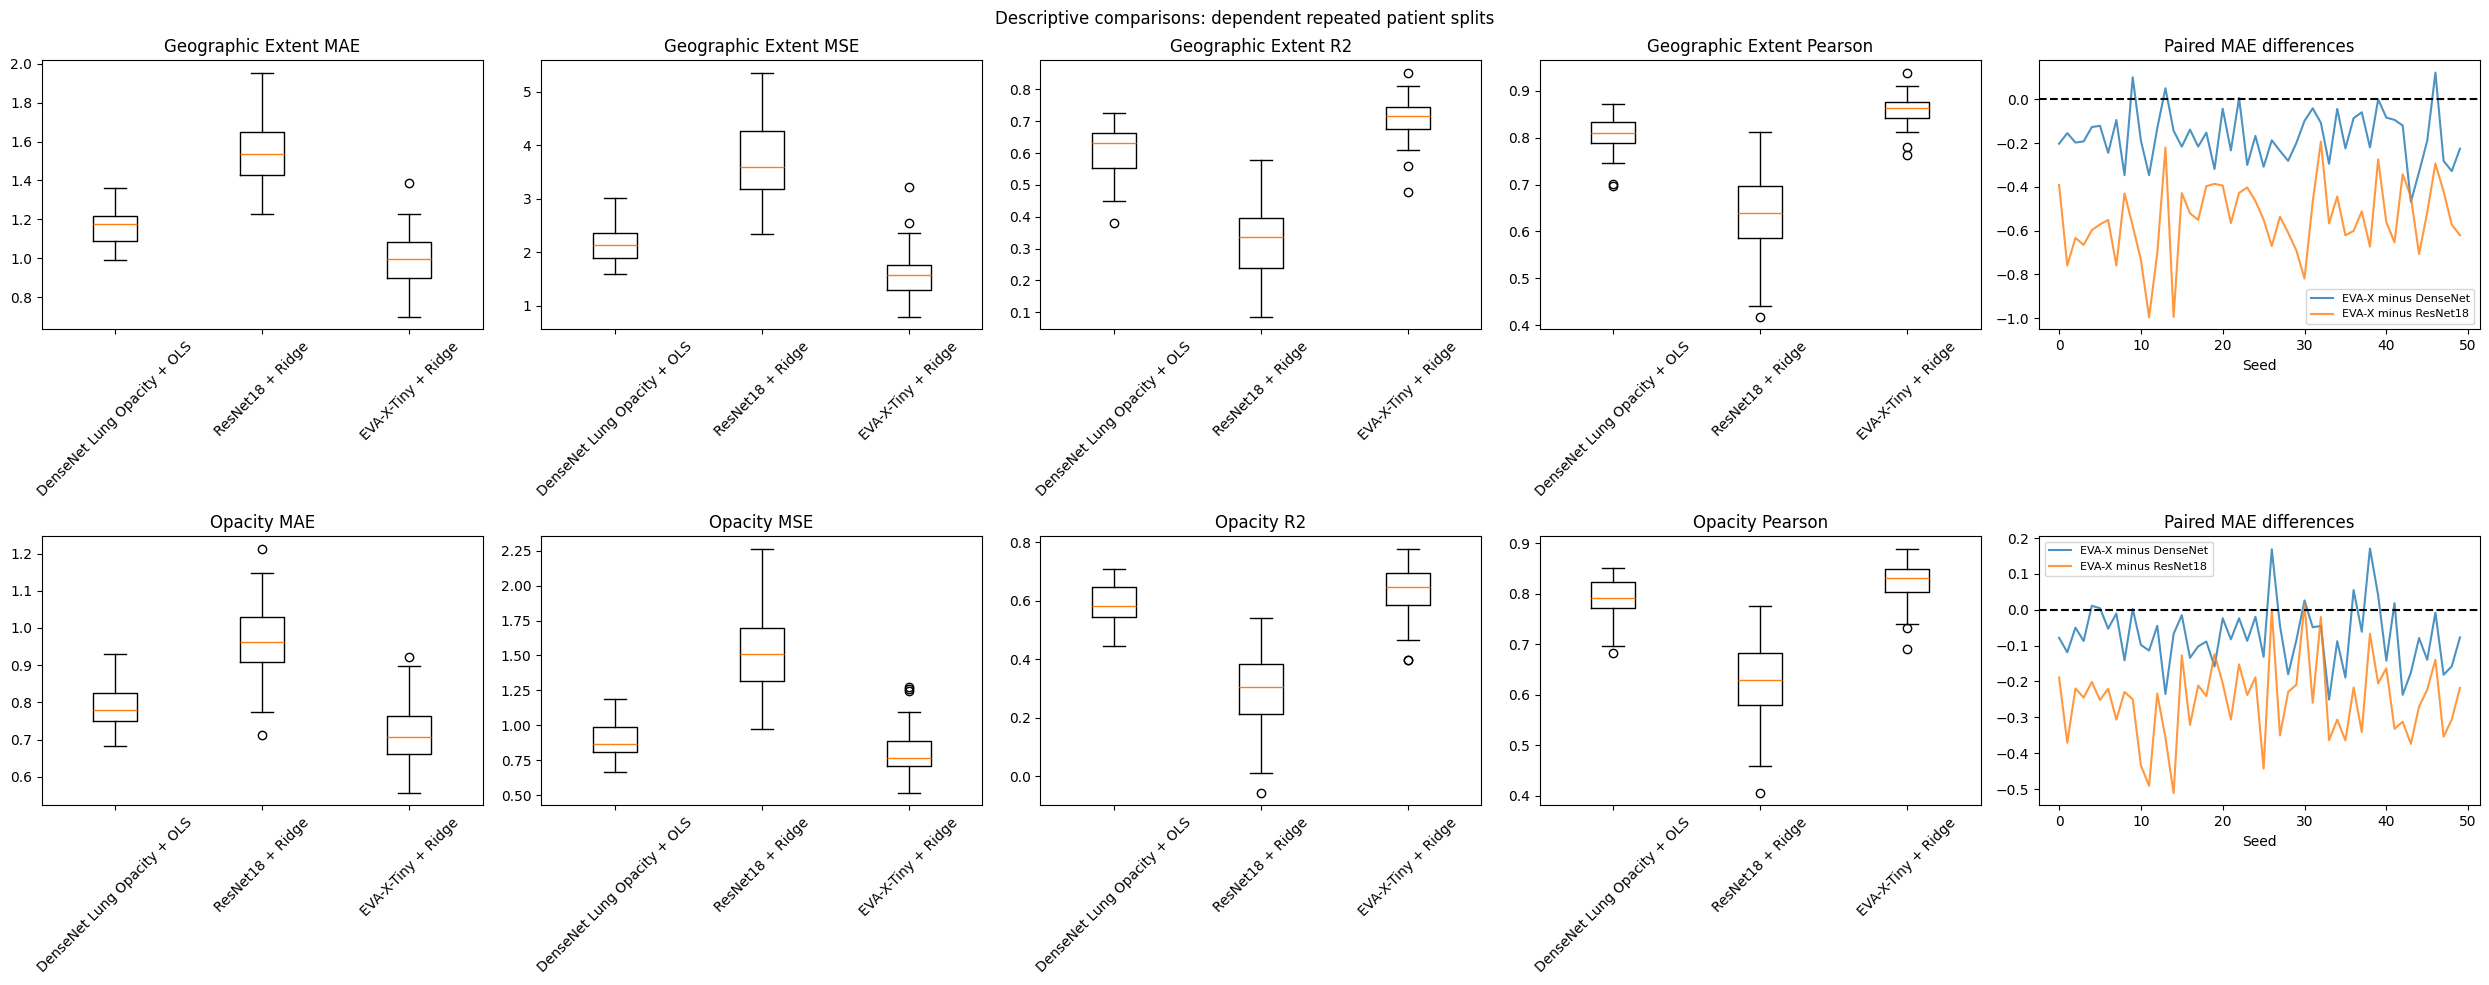

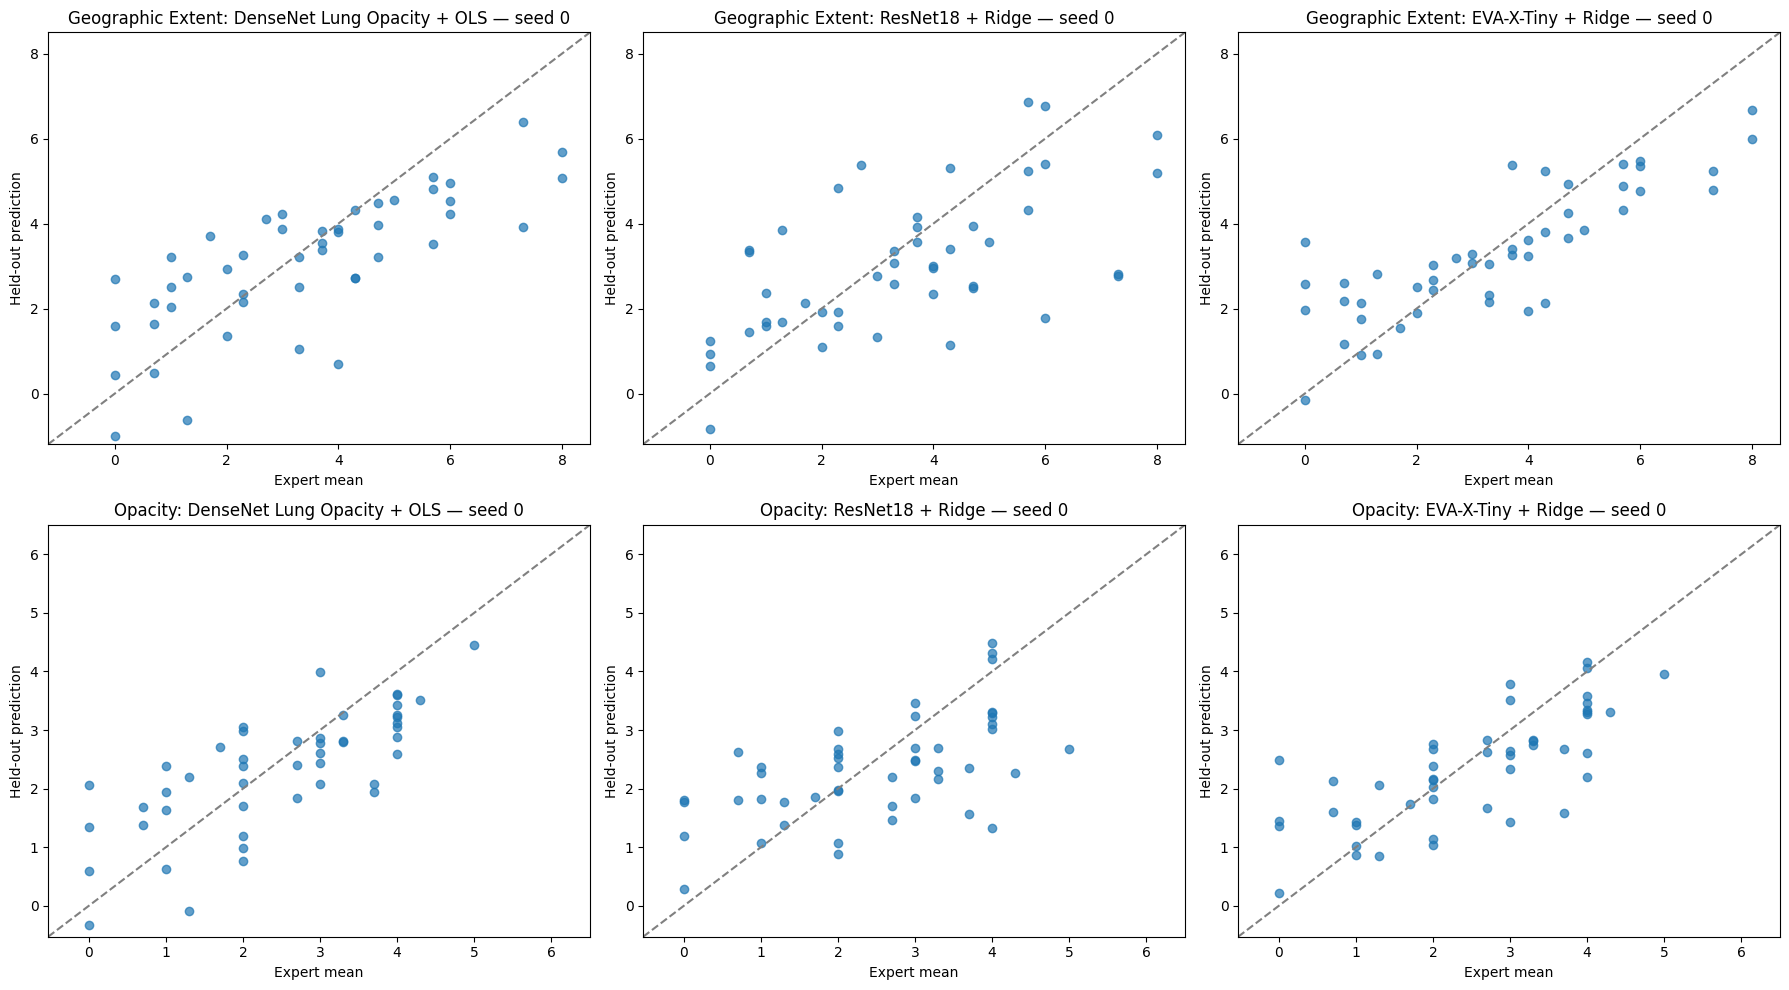

In [27]:
import matplotlib.pyplot as plt
models=[BASELINE,RIDGE,EVA_MODEL]
fig,axes=plt.subplots(2,5,figsize=(25,10))
for i,target in enumerate(['Geographic Extent','Opacity']):
    part=by_seed[by_seed.target==target]
    for j,metric in enumerate(['MAE','MSE','R2','Pearson']):
        axes[i,j].boxplot([part[part.model==m][metric].dropna() for m in models],labels=models)
        axes[i,j].tick_params(axis='x',rotation=45);axes[i,j].set_title(target+' '+metric)
    diff=paired.loc[target]
    for column in ['EVA-X minus DenseNet','EVA-X minus ResNet18']:
        axes[i,4].plot(diff.index,diff[column],label=column,alpha=.8)
    axes[i,4].axhline(0,linestyle='--',color='black');axes[i,4].set_title('Paired MAE differences')
    axes[i,4].set_xlabel('Seed');axes[i,4].legend(fontsize=8)
fig.suptitle('Descriptive comparisons: dependent repeated patient splits')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'three_model_comparison.png',dpi=180);plt.show()
fig,axes=plt.subplots(2,3,figsize=(18,10))
for i,(target,score_max) in enumerate([('Geographic Extent',8),('Opacity',6)]):
    p=predictions[(predictions.target==target)&(predictions.seed==SCATTER_SEED)]
    lo=min(-.5,float(p.y_pred.min())-.2);hi=max(score_max+.5,float(p.y_pred.max())+.2)
    for j,model in enumerate(models):
        q=p[p.model==model];axes[i,j].scatter(q.y_true,q.y_pred,alpha=.7)
        axes[i,j].plot([lo,hi],[lo,hi],'--',color='gray')
        axes[i,j].set(xlim=(lo,hi),ylim=(lo,hi),xlabel='Expert mean',ylabel='Held-out prediction',
                      title=f'{target}: {model} — seed {SCATTER_SEED}')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'eva_x_prediction_scatter.png',dpi=180);plt.show()


In [28]:
from pathlib import Path
import shutil

src = Path("/content/duong-eva-x-results")
dst = Path("/content/drive/MyDrive/duong-eva-x-results")

dst.mkdir(parents=True, exist_ok=True)

required = [
    "three_model_heldout_predictions.csv",
    "patient_split_audit.json",
    "reproducibility_manifest.json"
]

for name in required:
    assert (src / name).is_file(), f"Missing: {name}"
    shutil.copy2(src / name, dst / name)
    print("Saved:", name)

print("All files backed up successfully!")

Saved: three_model_heldout_predictions.csv
Saved: patient_split_audit.json
Saved: reproducibility_manifest.json
All files backed up successfully!


## Interpretation boundaries
This is a comparison of **complete frozen pretrained pipelines**, not architecture alone. EVA-X and DenseNet have CXR pretraining; ResNet18 uses ImageNet. Input preprocessing, pretraining objectives/populations, 192D versus 512D representations and single-logit versus regularized multivariate regression differ simultaneously. A new internal-performance difference would not isolate any one cause.

Only 65 labelled patients (94 images) support inference. Frozen transfer reduces supervised parameters but does not guarantee robustness. Expert score uncertainty and repeated patient observations limit precision. The 50 patient splits overlap and are dependent; report sample SD and descriptive paired differences, not naive independent-replication significance tests. Negative EVA-X minus baseline MAE favours EVA-X descriptively only. No test-set-directed alpha, crop, pooling or seed tuning is allowed.

**Potential pretraining overlap:** neither repository provenance nor new hashes establish disjointness between the Merged520k pretraining images, the CXR-pretrained DenseNet sources and this historical COVID cohort. Absence of patient overlap across our supervised train/test partitions does not eliminate upstream pretraining overlap. This remains unverified and requires upstream source manifests/deduplication. No external validation, clinical readiness or causal interpretation is established.

**Status:** the checkpoint smoke report must say passed in the current run before these experiments execute. Local cloud checkpoint access was blocked, so full pretrained compatibility and real-data results are unexecuted. No historical summary values are used to populate experiment outputs. Cache hits are reported and do not masquerade as fresh extraction timings.


In [4]:
import pandas as pd

path = "/content/drive/MyDrive/duong-data/metadata_2020.csv"
df = pd.read_csv(path)

print(df.columns.tolist())

# 查看许可类型分布
if "license" in df.columns:
    print(df["license"].fillna("UNKNOWN").value_counts())
else:
    print("License column not found; inspect source metadata.")

['patientid', 'offset', 'sex', 'age', 'finding', 'survival', 'intubated', 'intubation_present', 'went_icu', 'needed_supplemental_O2', 'extubated', 'temperature', 'pO2_saturation', 'leukocyte_count', 'neutrophil_count', 'lymphocyte_count', 'view', 'modality', 'date', 'location', 'folder', 'filename', 'doi', 'url', 'license', 'clinical_notes', 'other_notes', 'Unnamed: 27']
license
UNKNOWN                              163
CC BY-NC-SA                          140
CC BY-NC-SA 4.0                       23
CC BY-NC-ND                           14
Apache 2.0                            10
listed as authorized for everyone      7
CC BY                                  2
CC BY-SA                               1
Name: count, dtype: int64
